In [6]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
df = pd.read_csv("../../data/conv_credit_score_rate_spread.csv")
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 22091 entries, 0 to 22090
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   loan_sequence_number     22091 non-null  int64  
 1   pool_issue_date          22091 non-null  str    
 2   cusip                    22091 non-null  str    
 3   original_note_rate       22091 non-null  float64
 4   note_rate                22091 non-null  float64
 5   pmms_30yr_origination    22091 non-null  float64
 6   rate_spread              22091 non-null  float64
 7   original_loan_amt        22091 non-null  int64  
 8   credit_score             22091 non-null  int64  
 9   credit_score_category    22091 non-null  str    
 10  pmms_30yr_origination.1  22091 non-null  float64
dtypes: float64(5), int64(3), str(3)
memory usage: 1.9 MB
None


In [9]:
print(df[["credit_score"]].median())

credit_score    764.0
dtype: float64


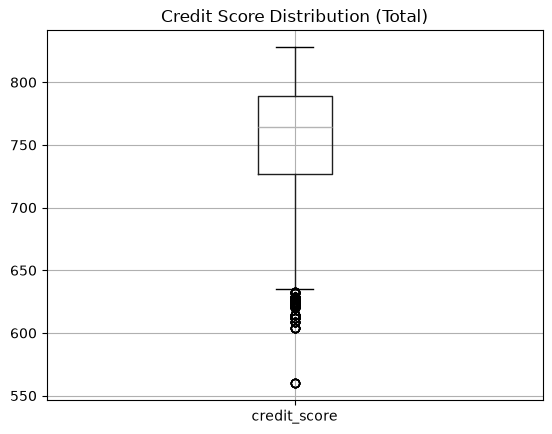

In [17]:
df.boxplot(column = ["credit_score"])
plt.title("Credit Score Distribution (Total)")
plt.show()

In [22]:
custom_order = ["Poor", "Fair", "Good", "Very Good", "Exceptional"]
df["credit_score_category"] = pd.Categorical(
    df["credit_score_category"],
    categories = custom_order,
    ordered = True
)


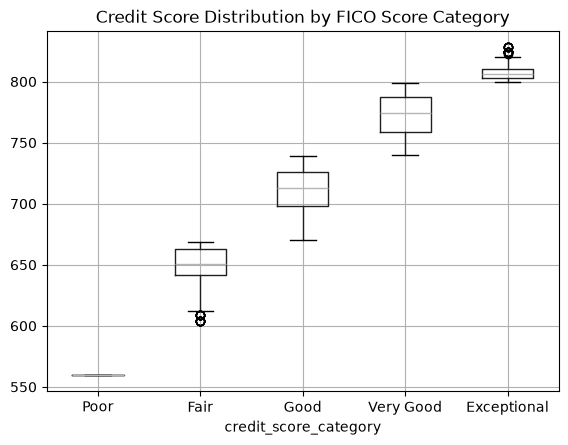

In [24]:
df.boxplot(column = "credit_score",
           by = "credit_score_category")
plt.title("Credit Score Distribution by FICO Score Category")
plt.suptitle("") 
plt.show()

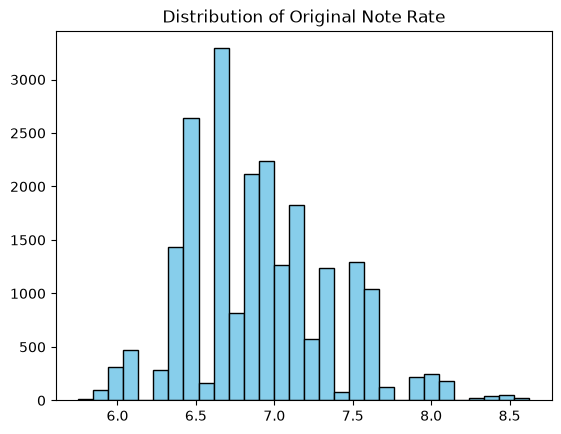

In [28]:
plt.hist(df["original_note_rate"].dropna(),
        bins = 30,
        edgecolor = "black",
        color = "skyblue")
plt.title("Distribution of Original Note Rate")
plt.show()

In [29]:
print(df["original_note_rate"].median())

6.875


In [30]:
print(df["original_note_rate"].mean())

6.910262244528541


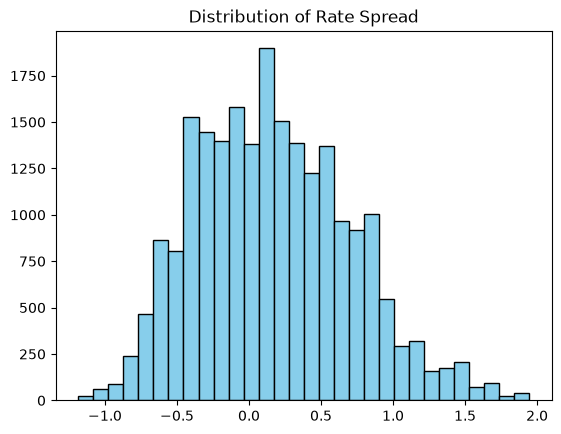

In [31]:
plt.hist(df["rate_spread"].dropna(),
        bins = 30,
        edgecolor = "black",
        color = "skyblue")
plt.title("Distribution of Rate Spread")
plt.show()

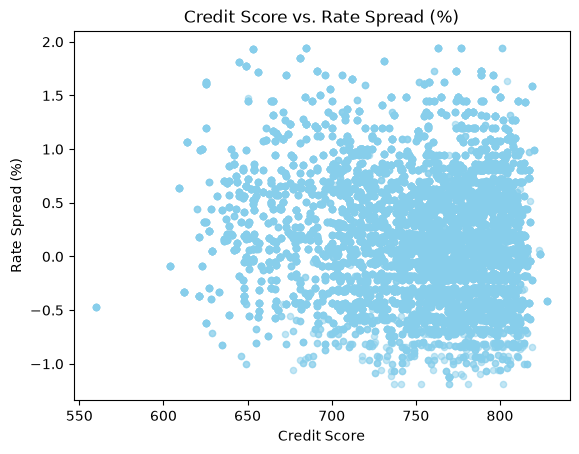

In [34]:
plt.scatter(
    df["credit_score"],
    df["rate_spread"],
    alpha = 0.5,
    s = 20,
    c = "skyblue"
)
plt.title("Credit Score vs. Rate Spread (%)")
plt.xlabel("Credit Score")
plt.ylabel("Rate Spread (%)")
plt.show()

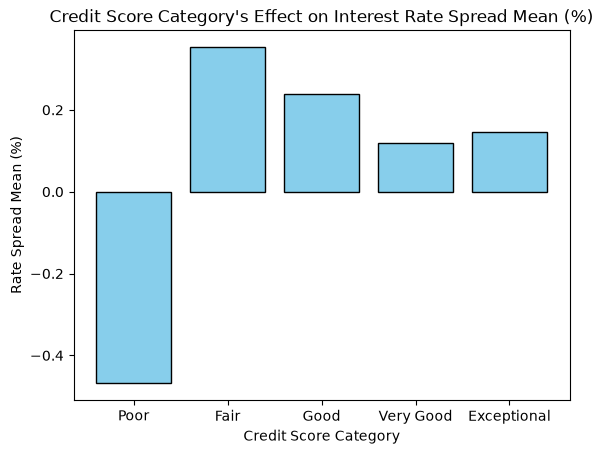

In [43]:
category_means = df.groupby("credit_score_category")["rate_spread"].mean()

plt.bar(
    category_means.index,
    category_means.values,
    color = "skyblue",
    edgecolor = "black"
)
plt.xlabel("Credit Score Category")
plt.ylabel("Rate Spread Mean (%)")
plt.title("Credit Score Category's Effect on Interest Rate Spread Mean (%)")
plt.show()

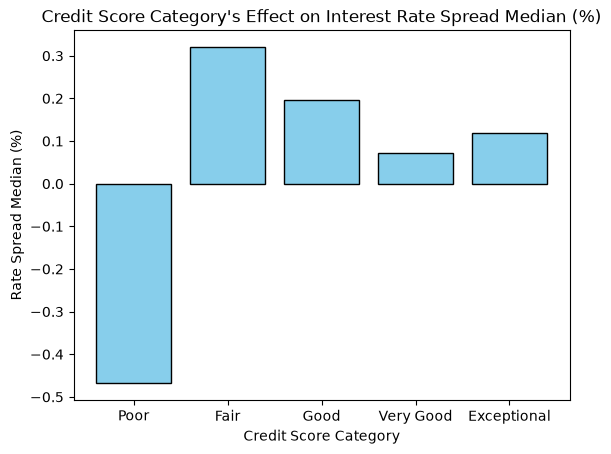

In [42]:
category_means = df.groupby("credit_score_category")["rate_spread"].median()

plt.bar(
    category_means.index,
    category_means.values,
    color = "skyblue",
    edgecolor = "black"
)
plt.xlabel("Credit Score Category")
plt.ylabel("Rate Spread Median (%)")
plt.title("Credit Score Category's Effect on Interest Rate Spread Median (%)")
plt.show()

In [44]:
print(df["credit_score"].isna().sum())

0


In [45]:
print(df["rate_spread"].isna().sum())

0


In [50]:
print(df[df["credit_score_category"] == "Poor"]["rate_spread"].describe())

count    6.000
mean    -0.468
std      0.000
min     -0.468
25%     -0.468
50%     -0.468
75%     -0.468
max     -0.468
Name: rate_spread, dtype: float64


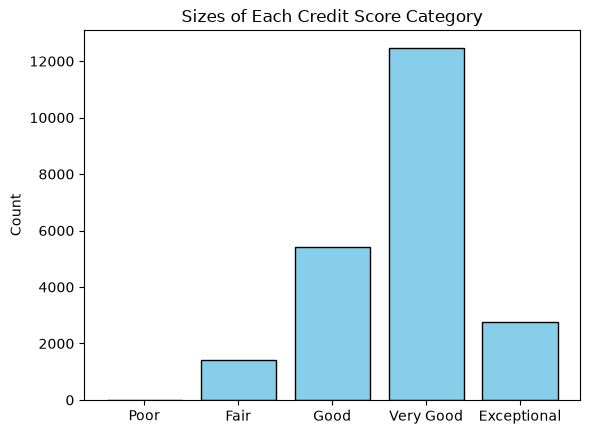

In [54]:
category_sizes = df.groupby("credit_score_category").size()

plt.bar(
    category_sizes.index,
    category_sizes.values,
    color = "skyblue",
    edgecolor = "black"
)
plt.title("Sizes of Each Credit Score Category")
plt.ylabel("Count")
plt.show()


In [56]:
poor = df[df["credit_score_category"] == "Poor"]
print(poor)

       loan_sequence_number pool_issue_date      cusip  original_note_rate  \
145              9850762395      2024-12-01  31425WJF9                6.49   
567              9850762395      2024-12-01  31425WJF9                6.49   
13802            9850762395      2024-12-01  31425WJF9                6.49   
15391            9850762395      2024-12-01  31425WJF9                6.49   
20125            9850762395      2024-12-01  31425WJF9                6.49   
20339            9850762395      2024-12-01  31425WJF9                6.49   

       note_rate  pmms_30yr_origination  rate_spread  original_loan_amt  \
145         6.49                  6.958       -0.468             320000   
567         6.49                  6.958       -0.468             320000   
13802       6.49                  6.958       -0.468             320000   
15391       6.49                  6.958       -0.468             320000   
20125       6.49                  6.958       -0.468             320000   
203